In [25]:
import os.path
import numpy as np
from numpy.linalg import norm
import pandas as pd
import matplotlib.pyplot as plt
import math

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit

from IPython.display import Image, display

from datetime import datetime

%matplotlib inline

In [26]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


# MLP

In [27]:
### --> Recebendo as colunas para separar X e Y
columns = ["atr1","atr2","atr3","atr4","atr5","atr6","atr7","atr8","class"]


### --> /MyDrive monta um drive no Colab e já pega os arquivos no Google Drive
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ML/Redes_Neurais/diab_dataset_train.txt', delimiter = "\t")

### --> Atribui os nomes das colunas às colunas do conjunto de dados
df.columns = columns

### --> Atribui apenas as colunas de atributos/features/entrada à X
X = df[["atr1","atr2","atr3","atr4","atr5","atr6","atr7","atr8"]]

### --> Transforma DataFrame pandas em numpy
X = X.to_numpy()
print(X.shape)

### --> Atribui apenas a coluna de saída ao Y
Yd = df[['class']].to_numpy()
print(Yd.shape)

(538, 8)
(538, 1)


In [28]:
# SESSÃO DE TESTE

### --> Recebendo as colunas para separar X e Y
columns_teste = ["atr1","atr2","atr3","atr4","atr5","atr6","atr7","atr8","class"]

### --> /MyDrive monta um drive no Colab e já pega os arquivos no Google Drive
df_teste = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/ML/Redes_Neurais/diab_dataset_teste.txt', delimiter = "\t")

### --> Atribui os nomes das colunas às colunas do conjunto de dados
df_teste.columns = columns_teste

### --> Atribui apenas as colunas de atributos/features/entrada à X
X_teste = df_teste[["atr1","atr2","atr3","atr4","atr5","atr6","atr7","atr8"]]

### --> Transforma DataFrame pandas em numpy
X_teste = X_teste.to_numpy()
print(X_teste.shape)

### --> Atribui apenas a coluna de saída ao Y
Yd_teste = df_teste[['class']].to_numpy()

N_teste = len(X_teste) ### quantidade de instâncias



(230, 8)


In [29]:
### Define os tamanhos de amostras, entradas e saídas
# X=0
N = len(X) ### quantidade de instâncias
ne = X.shape[1] ### quantidade de atributos
ns = Yd.shape[1] ### quantidade de saídas

X_val = X_teste
Yd_val = Yd_teste
N_val = len(X_val) ### quantidade de instâncias


# **Funções de Ativação:**


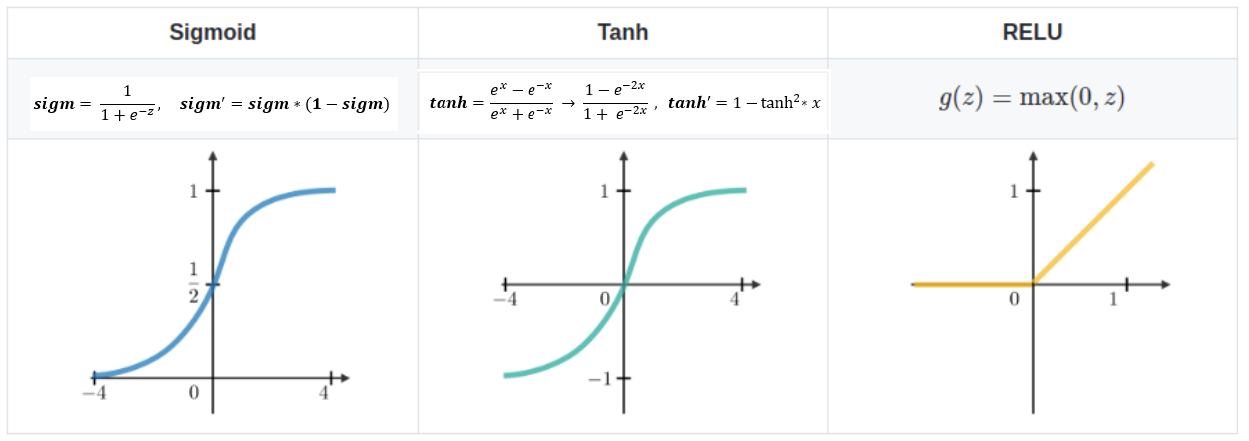

In [30]:
# Cria a função sigmoide
def sigmoid(Y):
  return 1 / (1 + np.exp(-Y))

# Cria a derivada da sigmoide
def dfsigmoid(Y):
  return Y*(1-Y)

# Cria a tangente hiperbólica
def tanh(Y):
  return (np.exp(Y) - np.exp(-Y)) / (np.exp(Y) + np.exp(-Y))

# Cria a derivada da tangente hiperbólica
def dftanh(Y):
  return 1-(Y**2)*Y

# Cria a Relu
def relu(Y):
  return np.maximum(0,Y)

# Cria a derivada da Relu
def dfrelu(Y):
    return np.maximum(0,Y)

def softmax(A):
  expA = np.exp(A)
  return expA / expA.sum(axis=1, keepdims=True)


# *Forward* de X até camada oculta

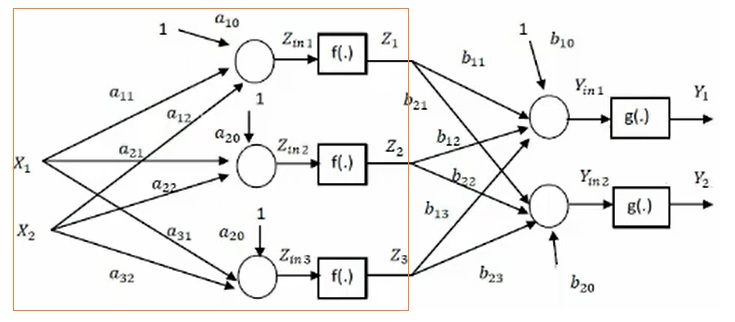

In [31]:

def x_ate_camada_oculta(X, a, a_bias):
  Z = sigmoid(np.matmul(X, a.T) + a_bias.T)
  return Z



# *Forward* da camada oculta até Y

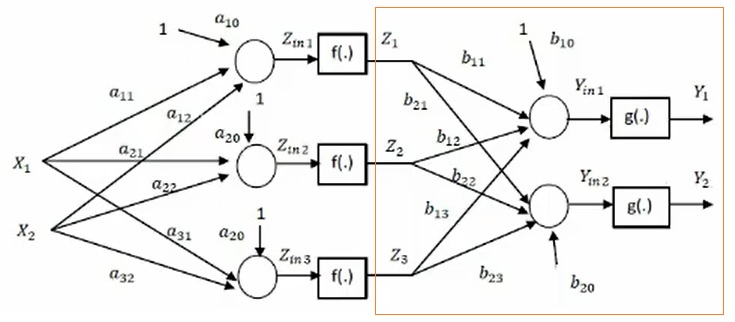

In [32]:
def camada_oculta_ate_Y(Z, b, b_bias):
  Y = np.matmul(Z, b.T) + b_bias.T
  return Y


# *Backward*

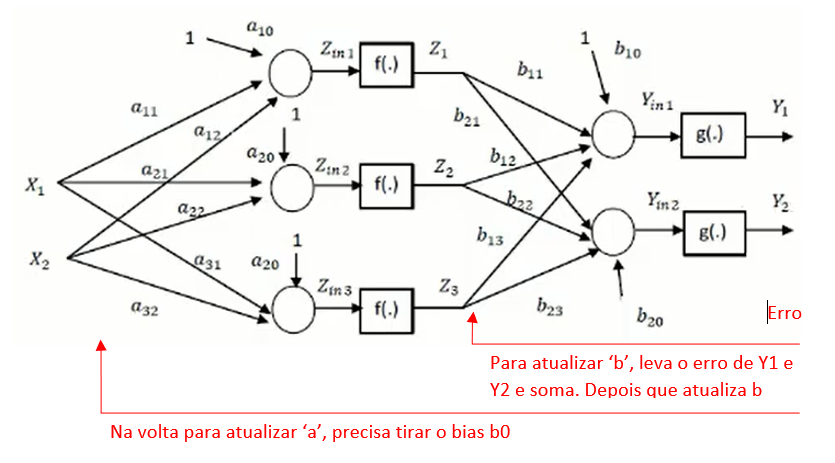

# Backpropation para atualização dos pesos **b**

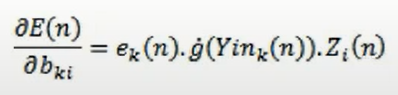

# Backpropation para atualização dos pesos **a**

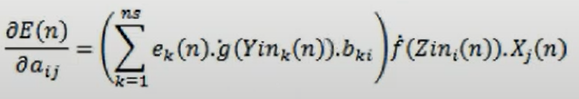

In [33]:
def gradiente_rna(X, Z, Yd, Y, a, a_bias, b, b_bias, v_a, v_a_bias, v_b, v_b_vias, tipo, hem, l2, momento):


  if l2 > 0:
    l2_norm = l2 * ((norm(a) + norm(b)))
  else:
    a_l2 = 0
    b_l2 = 0
    a_bias_l2 = 0
    b_bias_l2 = 0
    l2_norm = 0

  if momento > 0:
    b_momento = momento * v_b
    a_momento = momento * v_a
    b_bias_momento = momento * v_b_vias
    a_bias_momento = momento * v_a_bias
    v_a = a
    v_b = b
    v_a_bias = a_bias
    v_b_bias = b_bias
  else:
    b_momento = 0
    a_momento = 0
    b_bias_momento = 0
    a_bias_momento = 0

  if tipo == 'mlp':

    erro = Y-Yd

    if funcao_ativacao == 1:
      dEdA = np.matmul(erro, b) * dfsigmoid(Z)
    elif funcao_ativacao == 2:
      dEdA = np.matmul(erro, b) * dftanh(Z)
    else:
      dEdA = np.matmul(erro, b) * dfrelu(Z)

    b -= (learning_rate * (np.matmul(erro.T, Z) + l2_norm)) + momento
    a -= (learning_rate * (np.matmul(dEdA.T, X) + l2_norm)) + momento
    b_bias -= (learning_rate * (erro).sum(axis=0)) + momento
    a_bias -= (learning_rate * (dEdA).sum(axis=0)) + momento


  elif tipo == 'esp':

    erro = Y-Yd

    if funcao_ativacao == 1:
      dEdA = np.matmul(erro, b) * dfsigmoid(Z)
    elif funcao_ativacao == 2:
      dEdA = np.matmul(erro, b) * dftanh(Z)
    else:
      dEdA = np.matmul(erro, b) * dfrelu(Z)

    b -= (learning_rate * hem * (np.matmul(erro.T, Z))) + b_momento
    a -= (learning_rate * hem * (np.matmul(dEdA.T, X))) + a_momento
    b_bias -= (learning_rate * hem * (erro).sum(axis=0)) + b_bias_momento
    a_bias -= (learning_rate * hem * (dEdA).sum(axis=0)) + a_bias_momento


  elif tipo == 'gate':

    # print('Entrou na gating')
    erro = (Y-hem)

    if funcao_ativacao == 1:
      dEdA = np.matmul(erro, b) * dfsigmoid(Z)
    elif funcao_ativacao == 2:
      dEdA = np.matmul(erro, b) * dftanh(Z)
    else:
      dEdA = np.matmul(erro, b) * dfrelu(Z)

    b -= (learning_rate * (np.matmul(erro.T, Z))) + b_momento
    a -= (learning_rate * (np.matmul(dEdA.T, X) )) + a_momento
    b_bias -= (learning_rate * (erro).sum(axis=0)) + b_bias_momento
    a_bias -= (learning_rate * (dEdA).sum(axis=0)) + a_bias_momento

  return X, Z, Yd, Y, a, a_bias, b, b_bias, v_a, v_a_bias, v_b, v_b_vias, tipo, hem, l2, momento

def cross_entropy(Yd, Y):
  return -np.sum((Yd * (np.log(Y))))

In [34]:
def rna_mlp(X, Yd, h, N, tipo, v_a, v_b, hem, epmax, ep_val_parada, pesos, l2, momento, a_val, b_val, a_bias_val, b_bias_val):


  ns = Yd.shape[1] # quantidade de saídas

  if pesos == 'xavier':

    Fin_a = ne
    Fout_a = h
    limite_a = np.sqrt(6 / float(Fin_a + Fout_a))
    a = np.random.uniform(low=-limite_a, high=limite_a, size=(Fout_a, Fin_a))
    a_bias = np.random.uniform(low=-limite_a, high=limite_a, size=(h))

    Fin_b = h
    Fout_b = ns
    limite_b = np.sqrt(6 / float(Fin_b + Fout_b))
    b = np.random.uniform(low=-limite_b, high=limite_b, size=(Fout_b, Fin_b))
    b_bias = np.random.uniform(low=-limite_b, high=limite_b, size=(ns))

    print('Inicializando pesos usando método de Xavier')

  elif pesos == 'randomico':

    a = np.random.randn(h, ne)
    a_bias = np.random.randn(h)
    b = np.random.randn(ns, h)
    b_bias = np.random.randn(ns)
    a_val = a
    a_bias_val = a_bias
    b_val = b
    b_bias_val = b_bias
    print('Inicializando pesos de forma randômica')

  elif pesos == 'parada':
    a = a_val
    a_bias = a_bias_val
    b = b_val
    b_bias = b_bias_val
    print('Inicializando pesos da parada antecipada')


  v_a = 0
  v_b = 0
  v_a_bias = 0
  v_b_bias = 0

  ep = 0

  loss_treinamento = []
  loss_val = []
  loss_val_anterior = []
  parada = []
  loss_teste = []
  custo_anterior_val = 0
  tipo = tipo
  hem = hem

  ep_ini = 0
  ep_val_ini = 0


  while ep_ini < epmax:

    ep_ini += 1

    batch = N
    indice = np.random.randint(len(Yd))

    if X.shape[0] - indice < batch:
      X = X
      Yd = Yd
    else:
      X = X[indice:indice+batch]
      Yd = Yd[indice:indice+batch]


    Z = x_ate_camada_oculta(X, a, a_bias)
    Y = camada_oculta_ate_Y(Z, b, b_bias)

    Z_val = x_ate_camada_oculta(X_val, a, a_bias)
    Y_val = camada_oculta_ate_Y(Z_val, b, b_bias)

    Z_teste = x_ate_camada_oculta(X_teste, a, a_bias)
    Y_teste = camada_oculta_ate_Y(Z_teste, b, b_bias)

    # custo_atual = (-np.sum((Yd * (np.log(Y+ 1e-7))))/N)
    # custo_atual_val = (-np.sum((Yd_val * (np.log(Y_val+ 1e-7))))/N_val)
    # custo_atual_teste = (-np.sum((Yd_teste * (np.log(Y_teste+ 1e-7))))/N_teste)

    custo_atual = (-np.sum((Yd * (Y+ 1e-7)))/N)
    custo_atual_val = (-np.sum((Yd_val * (Y_val+ 1e-7)))/N_val)
    custo_atual_teste = (-np.sum((Yd_teste * (Y_teste+ 1e-7)))/N_teste)

    # if ep_ini == 1:
    #   custo_inicial = (-np.sum((Yd * (np.log(Y+ 1e-7))))/N)
    #   custo_inicial_val = (-np.sum((Yd_val * (np.log(Y_val+ 1e-7))))/N_val)
    #   custo_inicial_teste = (-np.sum((Yd_teste * (np.log(Y_teste+ 1e-7))))/N_teste)

    if ep_ini == 1:
      custo_inicial = 1
      custo_inicial_val = 1
      custo_inicial_teste = 1

    if custo_atual_val > custo_anterior_val:
      ep_val_ini += 1
      custo_anterior_val = custo_atual_val
      loss_treinamento.append(custo_atual)
      loss_val.append(custo_atual_val)
      loss_val_anterior.append(custo_anterior_val)

    else:
      custo_anterior_val = custo_atual_val
      loss_treinamento.append(custo_atual)
      loss_val.append(custo_atual_val)
      loss_val_anterior.append(custo_anterior_val)

    loss_treinamento.append(custo_atual)
    loss_val.append(custo_atual_val)
    loss_teste.append(custo_atual_teste)


    # writefile= open(arquivo,"w+")

    # with open(arquivo+'_error.txt', 'w') as writefile:
    #   writefile.write(f'\nLoss_treinamento: {loss_treinamento}')
    #   writefile.write(f'\nLoss_val: {loss_val}')
    #   writefile.write(f'\nLoss_teste: {loss_teste}')

    if ep_val_ini == ep_val_parada:
      parada = ep_ini
      print('Armazenou contador "parada"', parada, ep_ini)
      a_val = a
      a_bias_val = a_bias
      b_val = b
      b_bias_val = b_bias

    (X, Z, Yd, Y, a, a_bias, b, b_bias, v_a, v_a_bias, v_b, v_b_bias, tipo, hem, l2, momento) = gradiente_rna(X, Z, Yd, Y, a, a_bias, b, b_bias, v_a, v_a_bias, v_b, v_b_bias, tipo, hem, l2, momento)

  Y_cm = np.array([])
  Yd_cm = np.array([])
  for i in range (Yd.shape[0]):
    Y_cm = np.append(Y_cm, np.argmax(Y[i]))
    Yd_cm = np.append(Yd_cm, np.argmax(Yd[i]))

  Y_cm2 = Y_cm
  Yd_cm2 = Yd_cm

  print("\n***Estrutura do conjunto de dados*** ")
  print("X.shape:", X.shape, "Yd.shape: ", Yd.shape )
  print("X Validação.shape:", X_val.shape, "Yd Validação.shape: ", Yd_val.shape)
  print("Quantidade de instâncias: ", N+N_val)
  print("Quantidade de atributos: ", ne)
  print("Quantidade de saídas / classes / especialistas)", ns)

  print("\n***Estrutura da rede*** ")

  if funcao_ativacao == 1:
    print('\nFunção de Ativação: Sigmóide')
  elif funcao_ativacao == 2:
    print('\nFunção de Ativação: Tangente Hiperbólica')
  else:
    print('\nFunção de Ativação: Relu')

  print('\nTaxa de Momento: ', momento)
  print("Taxa de aprendizado", learning_rate)
  if pesos == 'randomico':
    print("Inicialização dos pesos randômica")
  elif pesos == 'xavier':
    print("Inicialização dos pesos com método Xavier")

  print('\nFoi até época: ', ep_ini)
  print('Parada Antecipada: ', parada)
  print('Épocas máxima: ', epmax)
  print("Quantidade de neurônios na camada oculta", h)

  print('\nCusto_inicial treinamento: ', custo_inicial)
  print('Custo_inicial validação: ', custo_inicial_val )
  print('Custo_inicial teste: ', custo_inicial_teste)
  print('\nCusto Atual Treinamento ', custo_atual)
  print('Custo Atual Validação ', custo_atual_val)
  print('Custo Atual Teste ', custo_atual_teste)

  print("\n")

  plt.plot(loss_treinamento, color = 'blue')
  plt.plot(loss_val, color = 'orange')
  plt.plot(loss_teste, color = 'green')
  # plt.plot(parada, color = 'red')
  plt.legend(['Treinamento', 'Validação', 'Teste'])
  plt.show()

  print('\n\nAcurácia (treinamento): ', 100*accuracy_score(Yd_cm2, Y_cm2), '%\n \n ')

  # with open(arquivo+'_config.txt', 'a') as writefile:
  #   writefile.write("\n")
  #   writefile.write(f"\n\n***Estrutura do conjunto de dados*** ")
  #   writefile.write(f"\nX.shape: {X.shape}, Yd.shape: {Yd.shape}")
  #   writefile.write(f"\nX Validação.shape: {X_val.shape}, Yd Validação.shape: {Yd_val.shape}")
  #   writefile.write(f"\nQuantidade de instâncias: {N}")
  #   writefile.write(f"\nQuantidade de atributos: {ne}")
  #   writefile.write(f"\nQuantidade de saídas / classes / especialistas {ns}")
  #   writefile.write(f"\n\n***Estrutura da rede*** ")

  #   if funcao_ativacao == 1:
  #     writefile.write('\nFunção de Ativação: Sigmóide')
  #   elif funcao_ativacao == 2:
  #     writefile.write('\nFunção de Ativação: Tangente Hiperbólica')
  #   else:
  #     writefile.write('\nFunção de Ativação: Relu')

  #   writefile.write(f'\nFoi até época: {ep_ini}')
  #   # writefile.write('Custo Atual Treinamento: { custo_atual})
  #   writefile.write(f'\nCusto Atual Validação {custo_atual_val}')
  #   writefile.write(f'\nCusto Anterior Validação: {custo_anterior_val}')
  #   writefile.write(f'\nParada Antecipada: {parada}')
  #   writefile.write(f'\nÉpocas máxima: {epmax}')
  #   writefile.write(f'\nTaxa de Momento: {momento}')
  #   writefile.write(f"\nTaxa de aprendizado: {learning_rate}")
  #   if pesos == 'randomico':
  #     writefile.write("\nInicialização dos pesos: randômica")
  #   elif pesos == 'xavier':
  #     writefile.write("\nInicialização dos pesos: método Xavier")
  #   writefile.write(f"\nQuantidade de neurônios na camada oculta: {h}")
  #   writefile.write(f'\n\nAcurácia (treinamento): 100*accuracy_score(Yd_cm2, Y_cm2)') #, '%\n \n '})

    # from numpy import asarray
    # from numpy import savetxt

    # a = np.asnumpy(a)
    # b = np.asnumpy(b)
    # a_bias = np.asnumpy(a_bias)
    # b_bias = np.asnumpy(b_bias)
    # a_val = np.asnumpy(a_val)
    # b_val = np.asnumpy(b_val)
    # a_bias_val = np.asnumpy(a_bias_val)
    # b_bias_val = np.asnumpy(b_bias_val)

    # savetxt(arquivo+'_model.csv', a, delimiter=',')
    # savetxt(arquivo+'_model.csv', b, delimiter=',')
    # savetxt(arquivo+'_model.csv', a_bias, delimiter=',')
    # savetxt(arquivo+'_model.csv', b_bias, delimiter=',')
    # savetxt(arquivo+'_model.csv', a_val, delimiter=',')
    # savetxt(arquivo+'_model.csv', b_val, delimiter=',')
    # savetxt(arquivo+'_model.csv', a_bias_val, delimiter=',')
    # savetxt(arquivo+'_model.csv', b_bias_val, delimiter=',')

    # with open(arquivo+'_model.txt', 'a') as writefilepesos:
    #   for i in range(a.shape[0]):
    #     writefilepesos.write(f"{a[i , :]}")
    #     writefilepesos.write(f"{a_bias[i , ]}")
    #     writefilepesos.write(f"{b[i , :]}")
    #     writefilepesos.write(f"{b_bias[i , ]}")
    #     # writefilepesos.write(f"{a_val[i , :]}")
    #     # writefilepesos.write(f"{a_bias_val[i , ]}")
    #     # writefilepesos.write(f"{b_val[i , :]}")
    #     # writefilepesos.write(f"{b_bias_val[i , ]}")

    # writefile.write(f'\nPesos a (treinamento): {a}, \n{a_bias}')
    # writefile.write(f'\nPesos "b" (treinamento): {b}, \n{b_bias}')
    # writefile.write(f'\nPesos "b" (treinamento): {a_val}, \n{a_bias_val}')
    # writefile.write(f'\nPesos "b" (treinamento): {b_val}, \n{b_bias_val}')


  return a, a_bias, b, b_bias, Y, Yd, epmax, loss_treinamento, v_a, v_b, epmax, ns, Yd_cm, Y_cm, a_val, a_bias_val, b_val, b_bias_val

def teste_rna(X_teste, Yd_teste, a_teste, b_teste, a_bias_teste, b_bias_teste):

  a_teste = np.array(a_teste)
  b_teste = np.array(b_teste)
  a_bias_teste = np.array(a_bias_teste)
  b_bias_teste = np.array(b_bias_teste)

  Z_teste = x_ate_camada_oculta(X_teste, a_teste, a_bias_teste)
  Y_pred  = camada_oculta_ate_Y(Z_teste, b_teste, b_bias_teste)

  Y_teste_cm = np.array([])
  Yd_teste_cm = np.array([])

  for i in range (Yd_teste.shape[0]):
      Y_teste_cm = np.append(Y_teste_cm, np.argmax(Y_pred[i]))
      Yd_teste_cm = np.append(Yd_teste_cm, np.argmax(Yd_teste[i]))

  Y_teste_cm2 = Y_teste_cm
  Yd_teste_cm2 = Yd_teste_cm

  print('\n\n\nAcurácia (teste): ', 100*accuracy_score(Yd_teste_cm2, Y_teste_cm2))





Inicializando pesos usando método de Xavier
Armazenou contador "parada" 11 11

***Estrutura do conjunto de dados*** 
X.shape: (538, 8) Yd.shape:  (538, 1)
X Validação.shape: (230, 8) Yd Validação.shape:  (230, 1)
Quantidade de instâncias:  768
Quantidade de atributos:  8
Quantidade de saídas / classes / especialistas) 1

***Estrutura da rede*** 

Função de Ativação: Sigmóide

Taxa de Momento:  0
Taxa de aprendizado 0.0001
Inicialização dos pesos com método Xavier

Foi até época:  150
Parada Antecipada:  11
Épocas máxima:  150
Quantidade de neurônios na camada oculta 5

Custo_inicial treinamento:  1
Custo_inicial validação:  1
Custo_inicial teste:  1

Custo Atual Treinamento  -0.13293615444075826
Custo Atual Validação  -0.13321288698327108
Custo Atual Teste  -0.13321288698327108




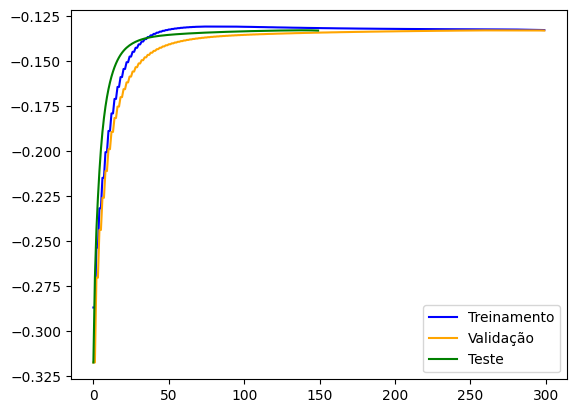



Acurácia (treinamento):  100.0 %
 
 



Acurácia (teste):  100.0


In [35]:
## Experimento:
# arquivo = 'MLP-Pior'
# k = 0

## Definição hiperparametros:

# Quantidade de neurônio
h = 5

# Taxa de aprendizado:
learning_rate = 0.0001

# Épocas máxima e parada antecipada:
epmax = 150
ep_val_parada = 10

## Definição parametros:

# Inicialização dos pesos:
pesos = 'xavier'
        # 'xavier' para inicializar os pesos usando o método Xavier
        # 'randomico' para inicializar os pesos randomicamente

# Funções de ativação
funcao_ativacao = 1
                  # 1 para sigmóide;
                  # 2 para tangente;
                  # 3 Relu
# Regularização:
l2 = 0

# Taxa de momento:
momento = 0
v_b = 0.0
v_a = 0.0

hem = 1 # valor = 1 para MLP, pois só será utilizado na Mistura de Especialistas


a_mlp, a_bias_mlp, b_mlp, b_bias_mlp, Y_mlp, Yd, epmax, loss, v_a, v_b, epmax, ns, Yd_cm_mlp, Y_cm_mlp, a_val, a_bias_val, b_val, b_bias_val = rna_mlp(X, Yd, h, N, 'mlp', v_a, v_b, hem, epmax, ep_val_parada, pesos, l2, momento, a_val=0, b_val=0, a_bias_val=0, b_bias_val=0)

teste_rna(X_teste, Yd_teste, a_mlp, b_mlp, a_bias_mlp, b_bias_mlp)


In [36]:
teste_rna(X_teste, Yd_teste, a_mlp, b_mlp, a_bias_mlp, b_bias_mlp)




Acurácia (teste):  100.0
